<a href="https://colab.research.google.com/github/itsabhi-21/Prognos/blob/main/notebooks/06_export_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prognos: Remaining Useful Life Prediction for Turbofan Engines
## Notebook 6: Exporting Predictions for the Demo App

**Goal:** Use the five saved GRU networks of each subset to predict the RUL at **every cycle** of every test engine (using only past cycles), so that the demo app can show a full RUL curve with an uncertainty band (spread of the five networks).

**Note:** For test engines, the true RUL is only known at the last cycle (from NASA's RUL file). Earlier values are derived as `RUL_last + (last cycle - cycle)`.

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from google.colab import drive

drive.mount('/content/drive')
PROC_DIR = '/content/drive/MyDrive/Prognos/processed'
OUT_DIR = '/content/drive/MyDrive/Prognos/demo'
os.makedirs(OUT_DIR, exist_ok=True)

SUBSETS = ['FD001', 'FD002', 'FD003', 'FD004']
CAP = 125
SHOW = ['s4', 's7', 's11', 's12']          # sensors shown in the app (normalised values)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
FEATS = json.load(open(f'{PROC_DIR}/features.json'))
print('device:', device)

Mounted at /content/drive
device: cpu


## 1. Model definition and loading
The same GRU as in Notebooks 5a/5b. The checkpoint of each subset contains the five trained networks and their hyperparameters.

In [2]:
class GRUNet(nn.Module):
    def __init__(self, n_feat, hidden, layers, dropout):
        super().__init__()
        self.rnn = nn.GRU(n_feat, hidden, layers, batch_first=True,
                          dropout=dropout if layers > 1 else 0.0)
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1]).squeeze(-1)

def predict(model, X):
    model.eval()
    outs = []
    with torch.no_grad():
        for i in range(0, len(X), 2048):
            outs.append(model(torch.tensor(X[i:i + 2048], dtype=torch.float32).to(device)).cpu())
    return torch.cat(outs).numpy()

def load_models(fd):
    ck = torch.load(f'{PROC_DIR}/models/gru_{fd}.pt', map_location=device, weights_only=False)
    p = ck['params']
    models = []
    for state in ck['states']:
        m = GRUNet(ck['n_feat'], p['hidden'], p['layers'], p['dropout']).to(device)
        m.load_state_dict(state)
        m.eval()
        models.append(m)
    return models, p

## 2. Preprocessing and windows for every test cycle
The test data is normalised with the training statistics of each operating condition (saved in Notebook 3), then a 30-cycle window is built for every cycle of every test engine (the start of an engine is padded with its first row, exactly as in Notebook 3).

In [3]:
def normalise(df, fd, feats):
    mean = pd.read_csv(f'{PROC_DIR}/scaler_{fd}_mean.csv', index_col=0)[feats]
    std = pd.read_csv(f'{PROC_DIR}/scaler_{fd}_std.csv', index_col=0)[feats]
    out = df.copy()
    out[feats] = (df[feats].values - mean.loc[df['cond'].values].values) / std.loc[df['cond'].values].values
    return out

def all_windows(df, feats, win=30):
    X = []
    for u, e in df.groupby('unit'):
        arr = e[feats].values.astype('float32')
        padded = np.pad(arr, ((win - 1, 0), (0, 0)), mode='edge')
        for i in range(len(e)):
            X.append(padded[i:i + win])
    return np.stack(X)

## 3. Predicting every cycle with the five-network ensemble
For each subset: predictions of the five networks are averaged (`pred_rul`), and their standard deviation (`pred_std`) is kept as a simple measure of model disagreement.
A check compares the prediction at the last cycle of each test engine with the file saved in Notebook 5b; they must agree.

In [4]:
frames = []
for fd in SUBSETS:
    te = pd.read_csv(f'{PROC_DIR}/test_{fd}_cond.csv').sort_values(['unit', 'cycle']).reset_index(drop=True)
    feats = FEATS[fd]
    te_n = normalise(te, fd, feats)

    models, p = load_models(fd)
    X = all_windows(te_n, feats)[:, -p['win']:, :]
    P = np.stack([predict(m, X) for m in models])             # (5 networks, n_rows)

    out = te[['unit', 'cycle']].copy()
    out.insert(0, 'subset', fd)
    out['pred_rul'] = P.mean(axis=0)
    out['pred_std'] = P.std(axis=0)

    rul_last = pd.read_csv(f'{PROC_DIR}/rul_{fd}.csv')['RUL'].values      # one row per test engine, in unit order
    units = np.sort(te['unit'].unique())
    last_cycle = te.groupby('unit')['cycle'].max()
    out['true_rul'] = (out['unit'].map(dict(zip(units, rul_last)))
                       + out['unit'].map(last_cycle) - out['cycle'])
    out['true_rul_capped'] = out['true_rul'].clip(upper=CAP)
    for s in SHOW:
        out[s] = te_n[s].values

    # sanity check against the predictions saved in Notebook 5b
    last = out.groupby('unit').tail(1)
    saved = pd.read_csv(f'{PROC_DIR}/predictions_{fd}.csv')
    diff = np.abs(last['pred_rul'].values - saved['predicted_RUL'].values).max()
    rm = float(np.sqrt(np.mean((last['pred_rul'].values - last['true_rul'].values) ** 2)))
    print(f'{fd}: rows {len(out)} | max diff vs saved predictions {diff:.5f} | ensemble RMSE at last cycle {rm:.2f}')
    frames.append(out)

demo = pd.concat(frames, ignore_index=True)

FD001: rows 13096 | max diff vs saved predictions 0.00012 | ensemble RMSE at last cycle 15.32
FD002: rows 33991 | max diff vs saved predictions 0.00012 | ensemble RMSE at last cycle 26.04
FD003: rows 16596 | max diff vs saved predictions 0.00015 | ensemble RMSE at last cycle 13.67
FD004: rows 41214 | max diff vs saved predictions 0.00012 | ensemble RMSE at last cycle 26.66


## 4. Saving the demo files
The predictions are saved as a compressed CSV, together with the result tables of Notebooks 3 and 5b that the app displays.

In [5]:
for c in ['pred_rul', 'pred_std', 'true_rul_capped'] + SHOW:
    demo[c] = demo[c].round(3)
demo['true_rul'] = demo['true_rul'].astype(int)

demo.to_csv(f'{OUT_DIR}/demo_data.csv.gz', index=False, compression='gzip')
pd.read_csv(f'{PROC_DIR}/final_results.csv').to_csv(f'{OUT_DIR}/final_results.csv', index=False)
pd.read_csv(f'{PROC_DIR}/baseline_results.csv').to_csv(f'{OUT_DIR}/baseline_results.csv', index=False)

for f in sorted(os.listdir(OUT_DIR)):
    print(f, round(os.path.getsize(f'{OUT_DIR}/{f}') / 1e6, 2), 'MB')

baseline_results.csv 0.0 MB
demo_data.csv.gz 2.05 MB
final_results.csv 0.0 MB


## 5. Visual check
One test engine of FD001: the predicted RUL (with the ensemble band) against the derived true RUL over the engine's life.

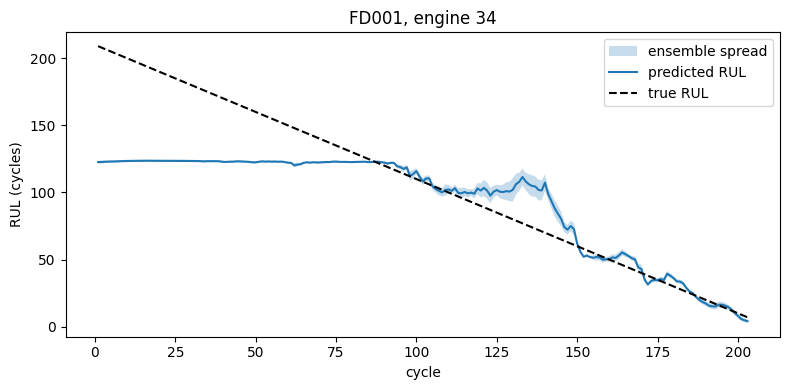

In [6]:
e = demo[(demo['subset'] == 'FD001') & (demo['unit'] == 34)].sort_values('cycle')
plt.figure(figsize=(8, 4))
plt.fill_between(e['cycle'], e['pred_rul'] - e['pred_std'], e['pred_rul'] + e['pred_std'], alpha=0.25, label='ensemble spread')
plt.plot(e['cycle'], e['pred_rul'], label='predicted RUL')
plt.plot(e['cycle'], e['true_rul'], 'k--', label='true RUL')
plt.xlabel('cycle'); plt.ylabel('RUL (cycles)'); plt.title('FD001, engine 34'); plt.legend()
plt.tight_layout(); plt.show()